# Multicore parallel performance of Spark

This notebook studies how the running time of the RDD example
[add_numbers_from_file.py](../src/rdd/add_numbers_from_file.py) changes when Spark runs in
local mode with 1, 2, 4, 8 and 16 cores (`local[N]`).

**Experimental design**

- Two input files created with `util.generate_numbers`: **500 million** and **1000 million**
  random integers, one per line.
- Core counts: 1, 2, 4, 8, 16.
- Every experiment (file, cores) is run **3 times**, each one in an independent process with
  its own JVM and its own `SparkContext`. The runs are interleaved (round 1 of all
  experiments, then round 2, ...) so that slow drifts of the machine (thermal throttling,
  background load) are spread over all the experiments.
- The measured time is the one taken by `add_numbers_from_file` (read + parse + reduce),
  measured with `time.perf_counter()` exactly as the example does; the start-up of the
  `SparkContext` is excluded.
- Experiments are run from the longest to the shortest.
- Results are appended to a CSV file after every run, so the notebook can be interrupted and
  re-executed: finished runs are not repeated.

**Metrics.** With $T_n$ the mean time with $n$ cores:
speed-up $S_n = T_1 / T_n$ and parallel efficiency $E_n = S_n / n$.

In [1]:
import json
import platform
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from util.generate_numbers import generate_numbers

DATA_DIR = Path("../data/output")
RESULTS_FILE = DATA_DIR / "multicore_results.csv"
SIZES = {"500M": 500_000_000, "1000M": 1_000_000_000}
CORES = [1, 2, 4, 8, 16]
RUNS = 3
SEED = 42

DATA_DIR.mkdir(parents=True, exist_ok=True)

## Machine

The speed-up cannot be interpreted without knowing the hardware.

In [2]:
def describe_machine() -> dict[str, str]:
    """Collect the hardware characteristics relevant for the study (macOS and Linux)."""

    def sysctl(name: str) -> str:
        result = subprocess.run(["sysctl", "-n", name], capture_output=True, text=True)
        return result.stdout.strip() if result.returncode == 0 else "n/a"

    memory_bytes = sysctl("hw.memsize")
    memory_gib = round(int(memory_bytes) / 2**30) if memory_bytes != "n/a" else "n/a"

    return {
        "platform": platform.platform(),
        "logical CPUs": str(__import__("os").cpu_count()),
        "performance cores": sysctl("hw.perflevel0.physicalcpu"),
        "efficiency cores": sysctl("hw.perflevel1.physicalcpu"),
        "memory (GiB)": str(memory_gib),
        "python": platform.python_version(),
    }


pd.Series(describe_machine(), name="value").to_frame()

,value
platform,macOS-26.6.2-arm64-arm-64bit
logical CPUs,18
performance cores,6
efficiency cores,12
memory (GiB),64
python,3.11.17


## Input files

The files are generated once with a fixed seed and reused afterwards (about 4 GB and 8 GB).

In [3]:
def ensure_input_file(label: str, count: int) -> Path:
    """Generate the file of ``count`` random integers if it does not exist yet.

    Args:
        label: Label of the size, used in the file name.
        count: Number of integers in the file.

    Returns:
        Path of the file.
    """
    path = DATA_DIR / f"numbers_{label}.txt"
    if not path.exists():
        start = time.perf_counter()
        generate_numbers(str(path), count, SEED)
        print(f"{path.name} generated in {time.perf_counter() - start:.0f} s")
    return path


input_files = {label: ensure_input_file(label, count) for label, count in SIZES.items()}
for label, path in input_files.items():
    print(f"{label}: {path.stat().st_size / 2**30:.2f} GiB")

500M: 1.81 GiB
1000M: 3.62 GiB


## Available parallelism

Spark runs one task per partition of the RDD, so a file can never use more cores than it has
partitions. In local mode `textFile` splits the file in chunks of about 32 MB.

In [4]:
from pyspark import SparkConf, SparkContext

# fmt: off
conf = (
    SparkConf()
    .setAppName("Partitions")
    .setMaster("local[1]")
)
# fmt: on

spark_context = SparkContext(conf=conf)
try:
    spark_context.setLogLevel("ERROR")
    partitions = {
        label: spark_context.textFile(str(path)).getNumPartitions()
        for label, path in input_files.items()
    }
finally:
    spark_context.stop()
partitions

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/opt/anaconda3/envs/spark420/lib/python3.11/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/10/14 10:36:35 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


{'500M': 58, '1000M': 116}

## Running one experiment

Each run is a fresh Python process that creates a `SparkContext` with `local[cores]` and calls
`add_numbers_from_file`, the function of the example program.

In [5]:
RUNNER = """
import json, sys, time
from pyspark import SparkConf, SparkContext
from rdd.add_numbers_from_file import add_numbers_from_file

cores, file_name = int(sys.argv[1]), sys.argv[2]

# fmt: off
conf = (
    SparkConf()
    .setAppName("Multicore")
    .setMaster(f"local[{cores}]")
)
# fmt: on

spark_context = SparkContext(conf=conf)
try:
    spark_context.setLogLevel("ERROR")
    start_time = time.perf_counter()
    result = add_numbers_from_file(spark_context, file_name)
    seconds = time.perf_counter() - start_time
finally:
    spark_context.stop()
print(json.dumps({"result": result, "seconds": seconds}))
"""


def run_experiment(cores: int, file_name: Path) -> dict:
    """Run the sum in an independent process and return its result and time.

    Args:
        cores: Number of cores given to Spark (``local[cores]``).
        file_name: Input file.

    Returns:
        A dictionary with the keys ``result`` and ``seconds``.
    """
    completed = subprocess.run(
        [sys.executable, "-c", RUNNER, str(cores), str(file_name)],
        capture_output=True,
        text=True,
        check=True,
    )
    return json.loads(completed.stdout.strip().splitlines()[-1])

In [6]:
def load_results() -> pd.DataFrame:
    """Read the results already stored on disk (empty if there are none)."""
    if RESULTS_FILE.exists():
        return pd.read_csv(RESULTS_FILE)
    return pd.DataFrame(columns=["size", "cores", "run", "result", "seconds"])


def pending_experiments() -> list[tuple[str, int]]:
    """List the experiments from the longest (largest file, fewest cores) to the shortest."""
    experiments = [(label, cores) for label in SIZES for cores in CORES]
    return sorted(experiments, key=lambda e: (-SIZES[e[0]], e[1]))


def run_all() -> pd.DataFrame:
    """Run every pending experiment, longest first, appending each result to the CSV file."""
    for run in range(1, RUNS + 1):
        for label, cores in pending_experiments():
            done = load_results()
            if ((done["size"] == label) & (done["cores"] == cores) & (done["run"] == run)).any():
                continue
            outcome = run_experiment(cores, input_files[label])
            row = pd.DataFrame([{"size": label, "cores": cores, "run": run, **outcome}])
            row.to_csv(RESULTS_FILE, mode="a", header=not RESULTS_FILE.exists(), index=False)
            seconds = outcome["seconds"]
            print(f"run {run} | {label:>5} | {cores:>2} cores | {seconds:8.1f} s", flush=True)
    return load_results()


results = run_all()

## Raw results

All the runs on the same file must produce the same sum, whatever the number of cores.

In [7]:
assert results.groupby("size")["result"].nunique().eq(1).all(), "inconsistent sums"
results.pivot_table(index=["size", "cores"], columns="run", values="seconds").round(1)

run              1      2      3
size  cores                     
1000M 1      277.8  255.5  252.1
      2      138.9  142.8  143.2
      4       79.2   81.6   82.4
      8       44.2   45.0   44.8
      16      28.1   28.6   28.1
500M  1      124.5  124.2  124.6
      2       71.3   71.3   71.4
      4       39.8   40.9   41.4
      8       23.6   23.7   24.1
      16      14.7   14.7   14.7

## Speed-up and efficiency

In [8]:
def summarize(results: pd.DataFrame) -> pd.DataFrame:
    """Compute mean time, standard deviation, speed-up and efficiency per experiment."""
    grouped = results.groupby(["size", "cores"])["seconds"]
    summary = grouped.agg(["mean", "std", "count"]).reset_index()
    baseline = summary[summary["cores"] == 1].set_index("size")["mean"]
    summary["speedup"] = summary["size"].map(baseline) / summary["mean"]
    summary["efficiency"] = summary["speedup"] / summary["cores"]
    summary["size"] = pd.Categorical(summary["size"], categories=list(SIZES), ordered=True)
    return summary.sort_values(["size", "cores"]).reset_index(drop=True)


summary = summarize(results)
summary.rename(columns={"count": "runs"}).round(
    {"mean": 1, "std": 1, "speedup": 2, "efficiency": 2}
)

,size,cores,mean,std,runs,speedup,efficiency
0,500M,1,124.4,0.2,3,1.00,1.00
1,500M,2,71.3,0.1,3,1.74,0.87
2,500M,4,40.7,0.8,3,3.06,0.76
3,500M,8,23.8,0.3,3,5.23,0.65
4,500M,16,14.7,0.0,3,8.48,0.53
5,1000M,1,261.8,14.0,3,1.00,1.00
6,1000M,2,141.6,2.3,3,1.85,0.92
7,1000M,4,81.1,1.7,3,3.23,0.81
8,1000M,8,44.7,0.4,3,5.86,0.73
9,1000M,16,28.3,0.2,3,9.26,0.58


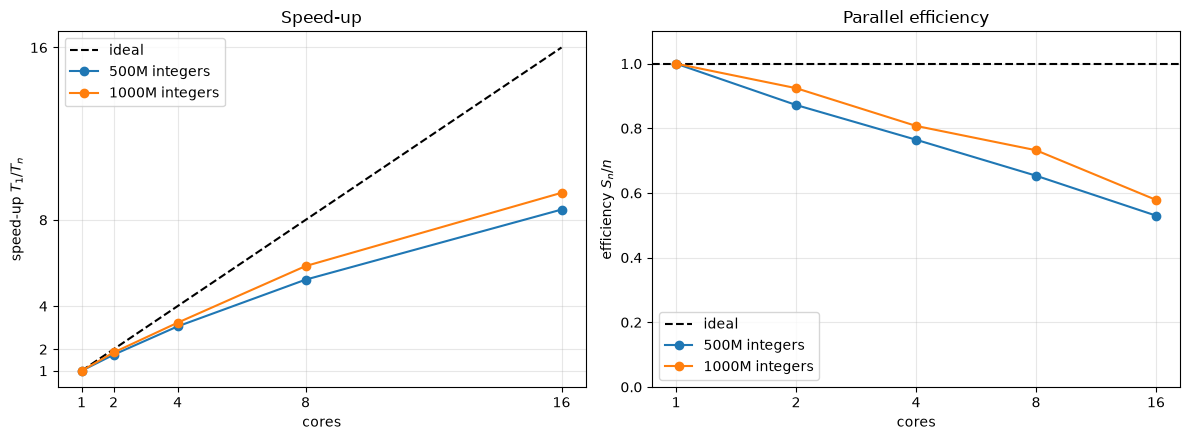

In [9]:
fig, (ax_speedup, ax_efficiency) = plt.subplots(1, 2, figsize=(12, 4.5))

ax_speedup.plot(CORES, CORES, "k--", label="ideal")
for label in SIZES:
    data = summary[summary["size"] == label]
    ax_speedup.plot(data["cores"], data["speedup"], "o-", label=f"{label} integers")
ax_speedup.set(xlabel="cores", ylabel="speed-up $T_1 / T_n$", title="Speed-up")
ax_speedup.set_xticks(CORES, [str(c) for c in CORES])
ax_speedup.set_yticks(CORES, [str(c) for c in CORES])
ax_speedup.minorticks_off()
ax_speedup.grid(alpha=0.3)
ax_speedup.legend()

ax_efficiency.axhline(1.0, color="k", linestyle="--", label="ideal")
for label in SIZES:
    data = summary[summary["size"] == label]
    ax_efficiency.plot(data["cores"], data["efficiency"], "o-", label=f"{label} integers")
ax_efficiency.set(
    xscale="log",
    ylim=(0, 1.1),
    xlabel="cores",
    ylabel="efficiency $S_n / n$",
    title="Parallel efficiency",
)
ax_efficiency.set_xticks(CORES, [str(c) for c in CORES])
ax_efficiency.minorticks_off()
ax_efficiency.grid(alpha=0.3)
ax_efficiency.legend()

fig.tight_layout()
fig.savefig(DATA_DIR / "multicore_speedup.png", dpi=150)
plt.show()

## How fast does the gain decay?

The **marginal gain** of every doubling of cores is the factor by which the time is divided when
going from $n/2$ to $n$ cores (2.0 would be perfect scaling).

In [10]:
def doubling_gain(summary: pd.DataFrame) -> pd.DataFrame:
    """Time reduction factor obtained each time the number of cores doubles."""
    table = summary.pivot(index="cores", columns="size", values="mean")
    gain = (table.shift(1) / table).dropna()
    steps = zip(CORES, CORES[1:], strict=False)
    gain.index = [f"{previous} -> {cores}" for previous, cores in steps]
    return gain


doubling_gain(summary).round(2)

size,500M,1000M
1 -> 2,1.74,1.85
2 -> 4,1.75,1.75
4 -> 8,1.71,1.81
8 -> 16,1.62,1.58


## Analysis

**Results.** Mean of 3 runs per configuration (the files have 58 and 116 partitions, so there are always more tasks than cores):

| cores | 500M time (s) | 500M speed-up | 1000M time (s) | 1000M speed-up |
| ----: | ------------: | ------------: | -------------: | -------------: |
| 1     | 124.4         | 1.00          | 261.8          | 1.00           |
| 2     | 71.3          | 1.74          | 141.6          | 1.85           |
| 4     | 40.7          | 3.06          | 81.1           | 3.23           |
| 8     | 23.8          | 5.23          | 44.7           | 5.86           |
| 16    | 14.7          | 8.48          | 28.3           | 9.26           |

**Spark scales well, but not ideally.** The time keeps going down all the way to 16 cores:
16 cores are 8.5x (500M) and 9.3x (1000M) faster than one, with an efficiency of 0.53-0.58.
Each doubling of the cores divides the time by 1.6-1.85 instead of the ideal 2.0, and the
factor is slightly lower for the last doubling (8 to 16 cores: 1.6).

**The larger file scales a little better**, as expected: the fixed costs of the job weigh less
when there is more work per core.

**Why the efficiency is below 1.** We have not measured it separately, but the likely causes
are the fixed cost of launching the job and the Python workers, all the tasks reading the same
disk, and the machine having 6 performance and 12 efficiency cores, so 16 "cores" are not 16
equal ones.

**Noise.** The runs agree closely (standard deviation below 1 s), except the 1-core runs
of 1000M (277.8, 255.5 and 252.1 s; std 14 s). The speed-ups of 1000M are therefore computed
from a less precise baseline.

**Conclusion.** With files of this size, adding cores keeps paying off up to 16 cores, though
each extra core contributes less than the previous one.
